# Seaborn basics — Penguins
## 1. Task
Explore how three penguin species differ by body measurements using seaborn charts.
## 2. Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## EDA

In [4]:
df = sns.load_dataset('penguins')
print(df.shape)
print(df.isna().sum())
df.head()

(344, 7)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [6]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


### EDA
two pinguins data is missing

mean and 50% precentile are almost identical, distibution is normal

## str values

In [15]:
print(df['sex'].unique())
print(df['sex'].value_counts())
print(df['sex'].isna().sum())

<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
sex
Male      168
Female    165
Name: count, dtype: int64
11


In [16]:
print(df['species'].unique())
print(df['species'].value_counts())
print(df['species'].isna().sum())

<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
0


In [17]:
print(df['island'].unique())
print(df['island'].value_counts())
print(df['island'].isna().sum())

<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
0


## distribution

(333, 7)


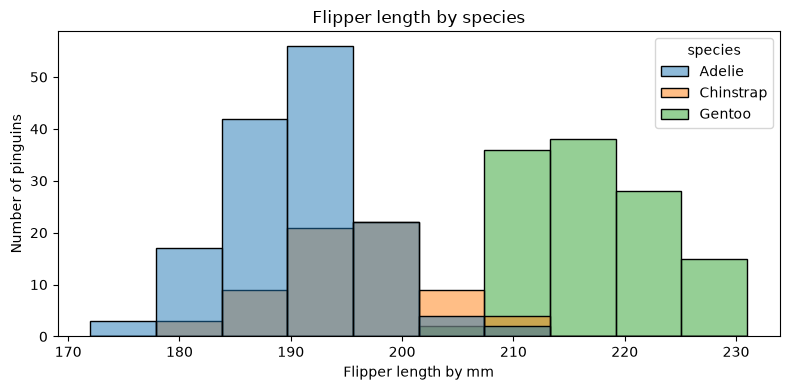

In [21]:
df = df.dropna()
print(df.shape)

fig, ax = plt.subplots(figsize=(8,4))

sns.histplot(data=df, x='flipper_length_mm', hue='species', ax=ax)
ax.set_title('Flipper length by species')
ax.set_xlabel('Flipper length by mm')
ax.set_ylabel('Number of pinguins')

fig.tight_layout()
plt.show()

## box plot

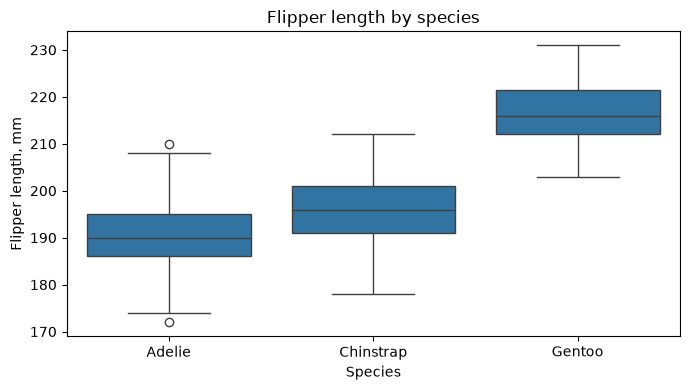

In [24]:
fig, ax = plt.subplots(figsize=(7,4))

sns.boxplot(data=df, x='species', y='flipper_length_mm', ax=ax)
ax.set_title('Flipper length by species')
ax.set_xlabel('Species')
ax.set_ylabel('Flipper length, mm')

fig.tight_layout()
plt.show()

## pairplot

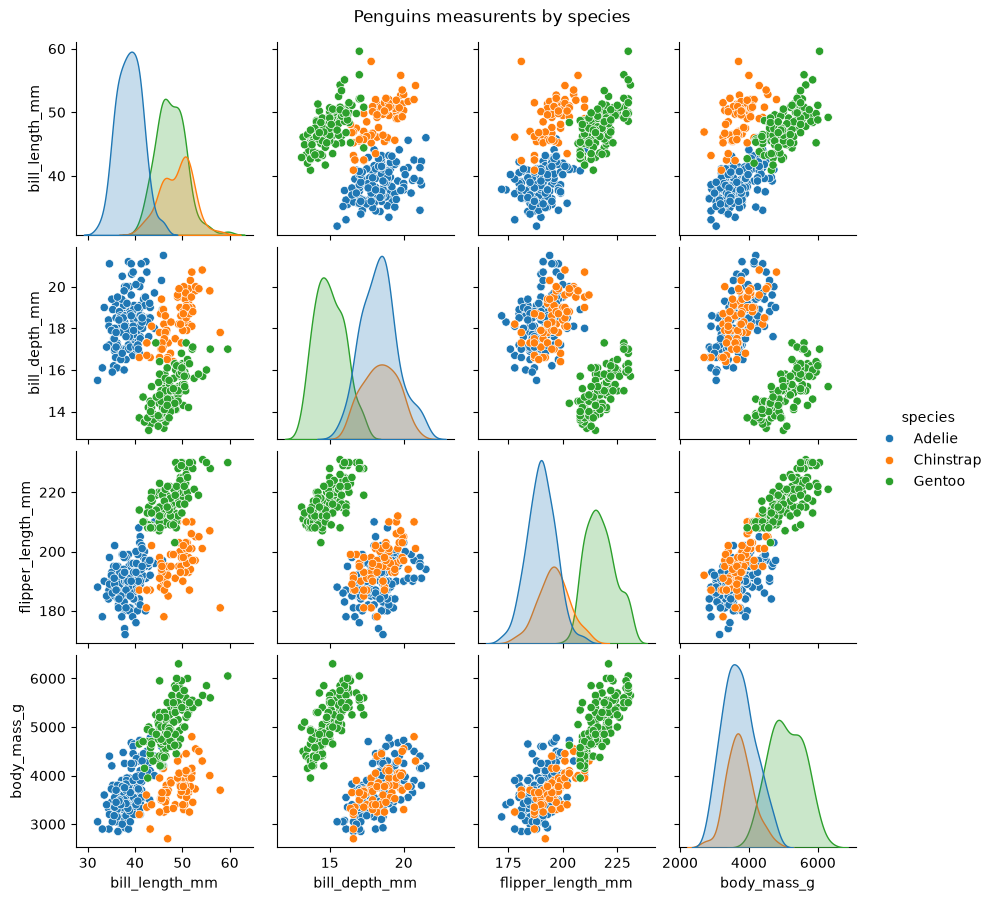

In [27]:
g = sns.pairplot(df, hue='species', height=2.2)
g.figure.suptitle('Penguins measurents by species', y=1.02)
plt.show()

# heatmap

                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm           1.000000      -0.228626           0.653096   
bill_depth_mm           -0.228626       1.000000          -0.577792   
flipper_length_mm        0.653096      -0.577792           1.000000   
body_mass_g              0.589451      -0.472016           0.872979   

                   body_mass_g  
bill_length_mm        0.589451  
bill_depth_mm        -0.472016  
flipper_length_mm     0.872979  
body_mass_g           1.000000  


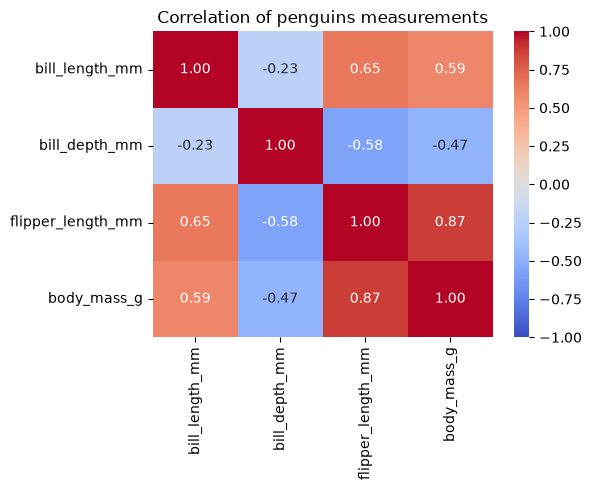

In [30]:
corr = df.corr(numeric_only=True)
print(corr)

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation of penguins measurements')
fig.tight_layout()
plt.show()

# exp

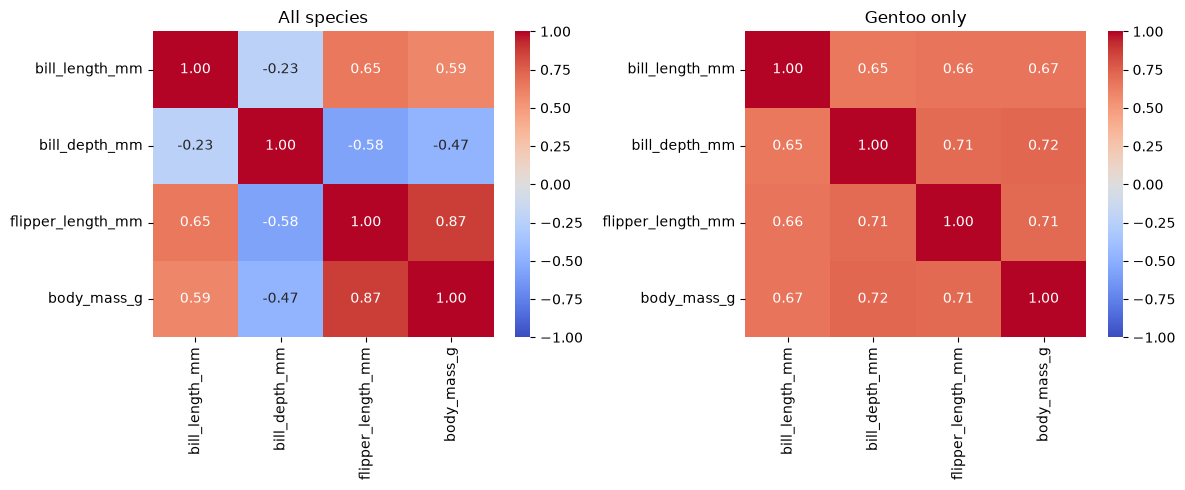

In [35]:
gentoo = df[df['species'] == 'Gentoo']
corr_gentoo = gentoo.corr(numeric_only=True)

fig, axes = plt.subplots(1,2, figsize=(12,5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('All species')
sns.heatmap(corr_gentoo, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Gentoo only')
fig.tight_layout()

plt.show()

# what i got

### seaborn vs matplotlib
- seaborn is a higher-level layer on top of matplotlib: it takes a DataFrame and column names
- `hue` colors the chart by category automatically (no for-loop like in VIZ-01)

### graphs best for
- histplot best to show distibution
- boxplot best to show distibitution amog specific spicies
- pairplot best to compare features pair by pair
- heatmap best to describe how features are interconnected with eachother, for numerica values
  
### Experiment
- across all species bill depth vs body mass = -0.47, inside Gentoo = +0.72
- mixing groups can flip a correlation (Simpson's paradox) — check by segment before concluding